# 🔍 Exploratory Data Analysis (EDA): AML Mule Account Detection
### Reserve Bank Innovation Hub (RBIH) - National Fraud Prevention Challenge

---
## Executive Overview
This notebook presents an end-to-end exploratory data analysis of the banking and transaction ecosystem for detecting money mule accounts. 

### Key Investigation Areas:
1. **Severe Class Imbalance**: Quantifying the 35:1 negative-to-positive ratio and its implications for evaluation metrics (PR-AUC vs Accuracy).
2. **Alert Reason Taxonomy**: Auditing 15 compliance alert typologies and separating genuine AML patterns from regulatory routine noise.
3. **Critical Red-Herrings & Traps**:
   - *Trap 1: The Account Freeze Illusion* (Over 4,100 legit accounts are frozen; >50% of real mules are currently active).
   - *Trap 2: Routine Investigation Noise* (26.3% of mules flagged without specific behavioral triggers).
   - *Trap 3: Temporal Out-of-Bounds Flag Dates* (Flag dates occurring outside the 2020–2025 transaction window).
4. **Government Schemes & Branch Geographies**: Analyzing PMJDY, APY, REGULAR schemes and rural/urban branch vulnerabilities.
5. **Transaction Behavioral Signatures**: Velocity, ₹50,000 PMLA structuring spikes, round-number transfers, and channel distributions.


In [1]:
# 1. Imports and Display Settings
import os
import glob
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 120

print(f"Polars Version: {pl.__version__}")


Polars Version: 1.44.1


## 1. Data Ingestion & Metadata Overview
We load the core relational tables:
- `train_labels.parquet`: Ground-truth labels (`is_mule`), alert reasons, flag dates.
- `accounts.parquet`: Core account details (status, branch, open date).
- `accounts-additional.parquet`: Scheme codes, debit card status, etc.
- `branch.parquet`: Branch tier (rural, semi-urban, urban) and regional metadata.
- `test_accounts.parquet`: Unlabelled target accounts for evaluation.


In [2]:
# Load tables using Polars for high performance
DATASET_DIR = "Dataset"

train_labels = pl.read_parquet(f"{DATASET_DIR}/train_labels.parquet")
test_accounts = pl.read_parquet(f"{DATASET_DIR}/test_accounts.parquet")
accounts = pl.read_parquet(f"{DATASET_DIR}/accounts.parquet")
accounts_add = pl.read_parquet(f"{DATASET_DIR}/accounts-additional.parquet")
branch = pl.read_parquet(f"{DATASET_DIR}/branch.parquet")
customers = pl.read_parquet(f"{DATASET_DIR}/customers.parquet")
linkage = pl.read_parquet(f"{DATASET_DIR}/customer_account_linkage.parquet")
demographics = pl.read_parquet(f"{DATASET_DIR}/demographics.parquet")

print("--- Dataset Inventory ---")
print(f"Train Accounts       : {len(train_labels):,}")
print(f"Test Accounts        : {len(test_accounts):,}")
print(f"Total Bank Accounts  : {len(accounts):,}")
print(f"Unique Customers     : {len(customers):,}")
print(f"Branches             : {len(branch):,}")


--- Dataset Inventory ---
Train Accounts       : 96,091
Test Accounts        : 64,062
Total Bank Accounts  : 160,153
Unique Customers     : 159,416
Branches             : 9,000


## 2. Class Imbalance & Metric Rationale
Detecting mule accounts involves severe class imbalance. A model predicting purely legitimate accounts (`0`) would achieve ~97.2% standard accuracy while failing 100% of AML compliance checks.


Total Training Records : 96,091
Legitimate Accounts (0): 93,408 (97.21%)
Mule Accounts (1)      : 2,683 (2.79%)
Class Imbalance Ratio  : 34.81 : 1


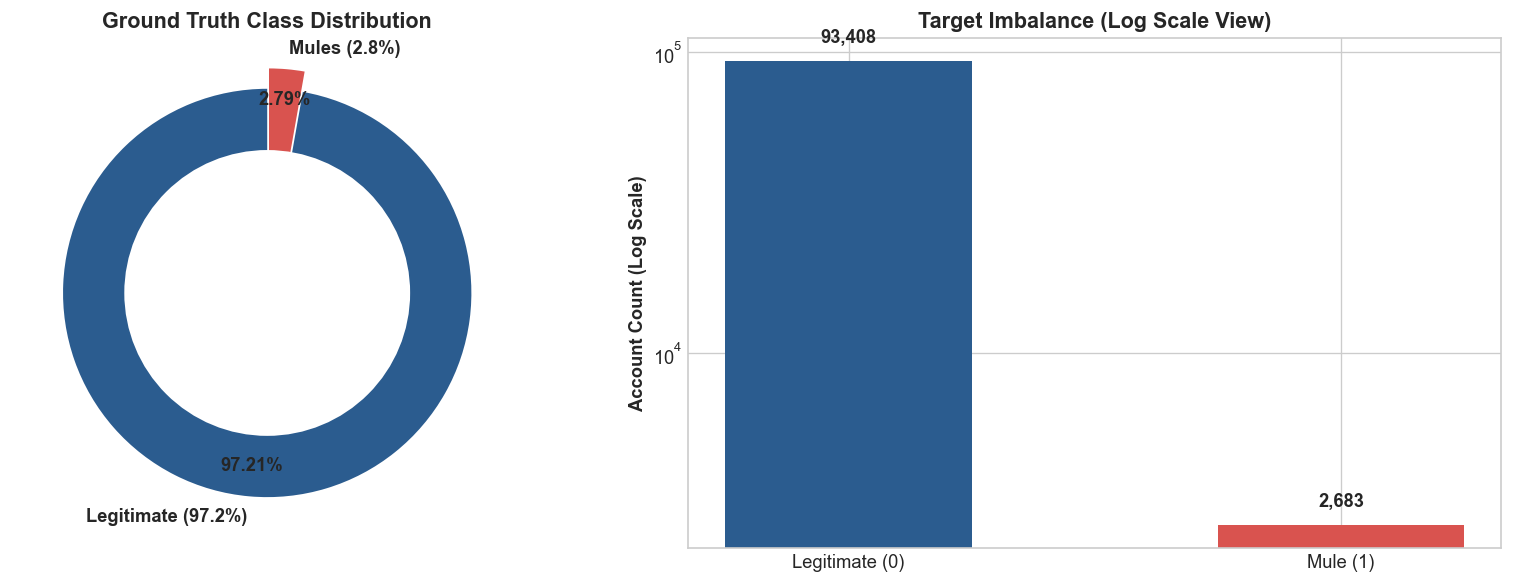

In [3]:
total_train = len(train_labels)
mule_count = train_labels.filter(pl.col("is_mule") == 1).shape[0]
legit_count = train_labels.filter(pl.col("is_mule") == 0).shape[0]
mule_pct = (mule_count / total_train) * 100
imbalance_ratio = legit_count / mule_count

print(f"Total Training Records : {total_train:,}")
print(f"Legitimate Accounts (0): {legit_count:,} ({100 - mule_pct:.2f}%)")
print(f"Mule Accounts (1)      : {mule_count:,} ({mule_pct:.2f}%)")
print(f"Class Imbalance Ratio  : {imbalance_ratio:.2f} : 1")

# Visualization: Class Balance
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Donut chart
colors = ['#2b5c8f', '#d9534f']
ax1.pie([legit_count, mule_count], labels=['Legitimate (97.2%)', 'Mules (2.8%)'],
        colors=colors, autopct='%1.2f%%', startangle=90, pctdistance=0.85,
        explode=(0, 0.1), textprops={'weight': 'bold'})
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
ax1.add_artist(centre_circle)
ax1.set_title("Ground Truth Class Distribution", weight='bold', fontsize=13)

# Log-scale count bar chart
bars = ax2.bar(['Legitimate (0)', 'Mule (1)'], [legit_count, mule_count], color=colors, width=0.5)
ax2.set_yscale('log')
ax2.set_ylabel("Account Count (Log Scale)", weight='bold')
ax2.set_title("Target Imbalance (Log Scale View)", weight='bold', fontsize=13)
for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, yval * 1.15, f"{int(yval):,}", ha='center', weight='bold')

plt.tight_layout()
plt.show()


## 3. Compliance Alert Reasons & AML Typologies
The training set labels are annotated with compliance triggers. Let's inspect the alert reason frequencies among confirmed mules.


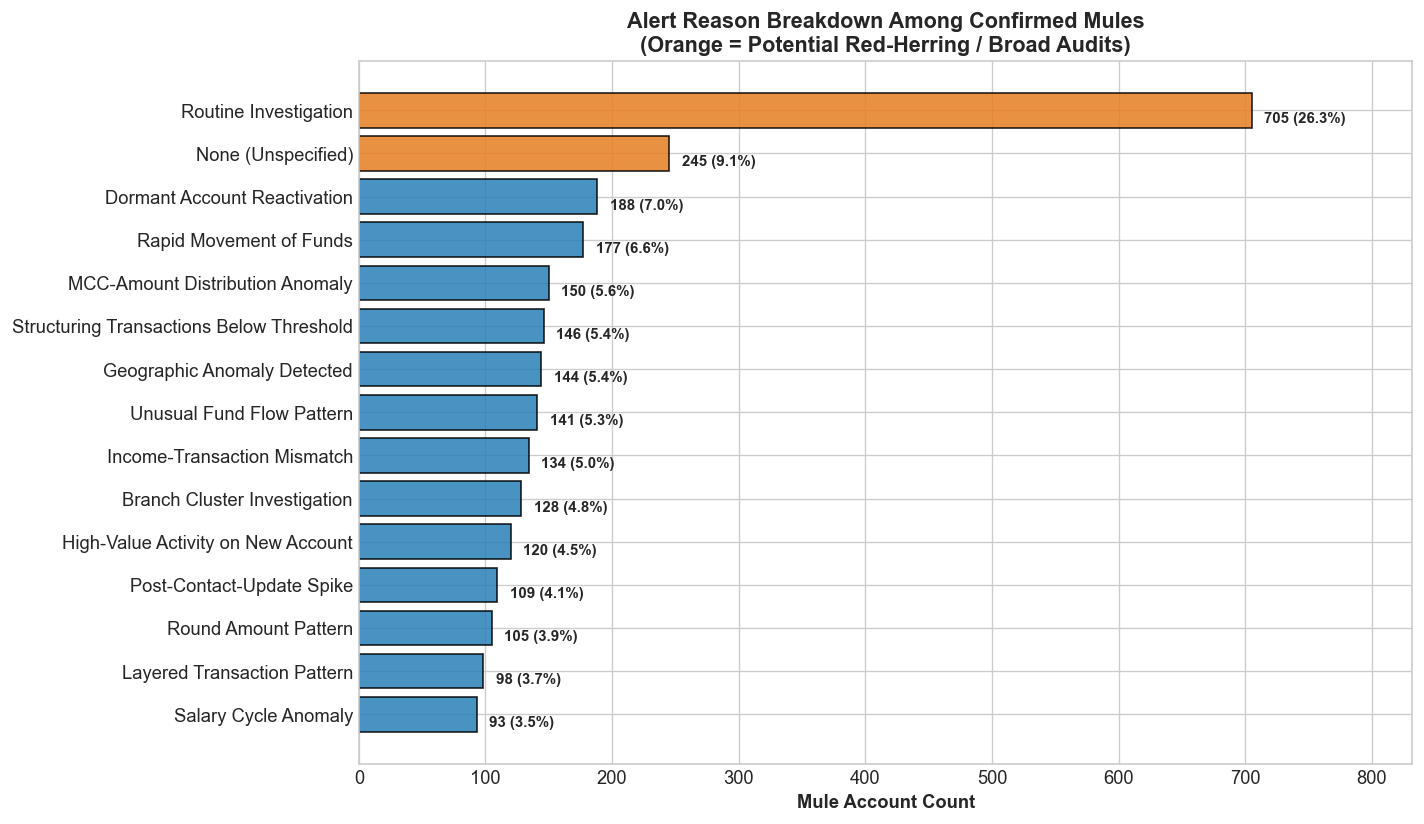

,alert_reason,len,percentage
0,Routine Investigation,705,26.276556
1,None (Unspecified),245,9.131569
2,Dormant Account Reactivation,188,7.007082
3,Rapid Movement of Funds,177,6.597093
4,MCC-Amount Distribution Anomaly,150,5.590757
5,Structuring Transactions Below Threshold,146,5.441670
6,Geographic Anomaly Detected,144,5.367126
7,Unusual Fund Flow Pattern,141,5.255311
8,Income-Transaction Mismatch,134,4.994409
9,Branch Cluster Investigation,128,4.770779


In [4]:
alert_summary = (
    train_labels.filter(pl.col("is_mule") == 1)
    .group_by("alert_reason")
    .len()
    .sort("len", descending=True)
    .to_pandas()
)
alert_summary["percentage"] = (alert_summary["len"] / mule_count) * 100
alert_summary["alert_reason"] = alert_summary["alert_reason"].fillna("None (Unspecified)")

# Bar chart of alert reasons
plt.figure(figsize=(12, 7))
palette = ['#e67e22' if r in ['Routine Investigation', 'None (Unspecified)'] else '#2980b9' 
           for r in alert_summary["alert_reason"]]

bars = plt.barh(alert_summary["alert_reason"][::-1], alert_summary["len"][::-1], color=palette[::-1], edgecolor='black', alpha=0.85)
plt.xlabel("Mule Account Count", weight='bold')
plt.title("Alert Reason Breakdown Among Confirmed Mules\n(Orange = Potential Red-Herring / Broad Audits)", weight='bold', fontsize=13)

for bar in bars:
    w = bar.get_width()
    pct = (w / mule_count) * 100
    plt.text(w + 10, bar.get_y() + bar.get_height()/4, f"{int(w)} ({pct:.1f}%)", va='center', fontsize=9, weight='bold')

plt.xlim(0, max(alert_summary["len"]) * 1.18)
plt.tight_layout()
plt.show()

alert_summary.head(10)


## 4. Red-Herrings & Feature Traps Deep Dive

### ⚠️ Trap 1: The Account Freeze Illusion (`account_status = 'frozen'`)
Intuition suggests that frozen accounts are mules. However, empirical inspection shows:
1. **Thousands of legitimate accounts are frozen** due to KYC non-compliance, minimum balance issues, or customer requests.
2. **Over 50% of confirmed mules are still 'active'**!


--- Account Status Cross-Tabulation ---


is_mule,Legitimate (0),Mule (1),Total,Mule_Rate_%
account_status,,,,
active,89211,1365,90576,1.507022
frozen,4197,1318,5515,23.898459


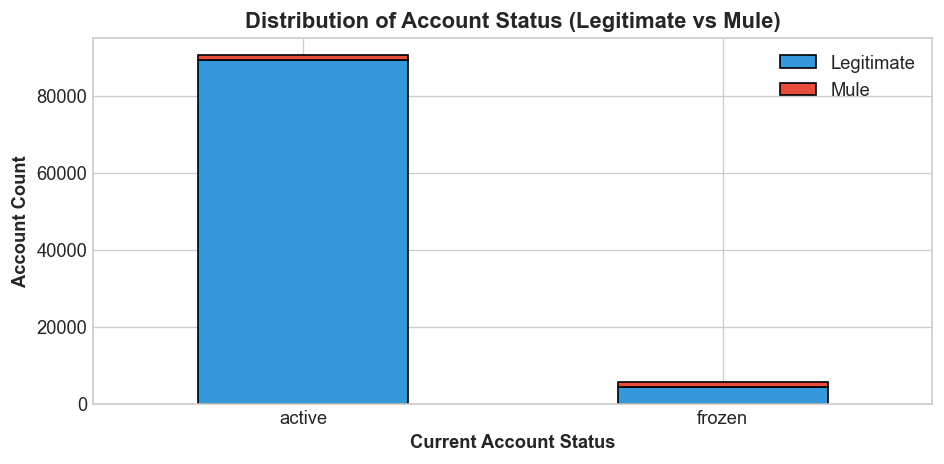

In [5]:
# Merge accounts with labels
train_merged = train_labels.join(accounts, on="account_id", how="left")
train_merged = train_merged.join(accounts_add, on="account_id", how="left")
train_merged = train_merged.join(branch, on="branch_code", how="left")

status_cross = (
    train_merged.group_by(["account_status", "is_mule"])
    .len()
    .to_pandas()
    .pivot(index="account_status", columns="is_mule", values="len")
    .fillna(0)
    .rename(columns={0: "Legitimate (0)", 1: "Mule (1)"})
)
status_cross["Total"] = status_cross["Legitimate (0)"] + status_cross["Mule (1)"]
status_cross["Mule_Rate_%"] = (status_cross["Mule (1)"] / status_cross["Total"]) * 100

print("--- Account Status Cross-Tabulation ---")
display(status_cross)

# Visualizing Freeze Trap
fig, ax = plt.subplots(figsize=(8, 4))
status_cross[["Legitimate (0)", "Mule (1)"]].plot(kind='bar', stacked=True, ax=ax, color=['#3498db', '#e74c3c'], edgecolor='black')
plt.title("Distribution of Account Status (Legitimate vs Mule)", weight='bold')
plt.ylabel("Account Count", weight='bold')
plt.xlabel("Current Account Status", weight='bold')
plt.xticks(rotation=0)
plt.legend(["Legitimate", "Mule"])
plt.tight_layout()
plt.show()


### ⚠️ Trap 2 & 3: Out-of-Bounds Flag Dates
The transaction dataset partitions span **July 1, 2020 to June 30, 2025**.
When aligning training data with transaction bursts, beware:
- Some accounts have `mule_flag_date` years before July 2020 or after June 2025.


In [6]:
mules_meta = train_merged.filter(pl.col("is_mule") == 1)

min_date = mules_meta["mule_flag_date"].min()
max_date = mules_meta["mule_flag_date"].max()
pre_window = mules_meta.filter(pl.col("mule_flag_date") < "2020-07-01").shape[0]
post_window = mules_meta.filter(pl.col("mule_flag_date") > "2025-06-30").shape[0]
in_window = mules_meta.filter(
    (pl.col("mule_flag_date") >= "2020-07-01") & (pl.col("mule_flag_date") <= "2025-06-30")
).shape[0]

print(f"Earliest Mule Flag Date : {min_date}")
print(f"Latest Mule Flag Date   : {max_date}")
print(f"Flags Before July 2020  : {pre_window:,}")
print(f"Flags After June 2025   : {post_window:,}")
print(f"Flags Within 5-Yr Window: {in_window:,}")


Earliest Mule Flag Date : 2015-09-05
Latest Mule Flag Date   : 2026-03-20
Flags Before July 2020  : 46
Flags After June 2025   : 754
Flags Within 5-Yr Window: 1,883


## 5. Government Schemes & Branch Profiles
Let's analyze vulnerability across Government Schemes (e.g. PMJDY financial inclusion accounts, APY pensions, SCSS) and Branch Tiers (Rural vs Semi-Urban vs Urban).


C:\Users\sashwat puri sachdev\AppData\Local\Temp\ipykernel_27220\1389328745.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=scheme_df.index, y=scheme_df["Mule_Rate_%"], ax=ax1, palette="mako", edgecolor="black")
C:\Users\sashwat puri sachdev\AppData\Local\Temp\ipykernel_27220\1389328745.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=branch_df.index, y=branch_df["Mule_Rate_%"], ax=ax2, palette="crest", edgecolor="black")


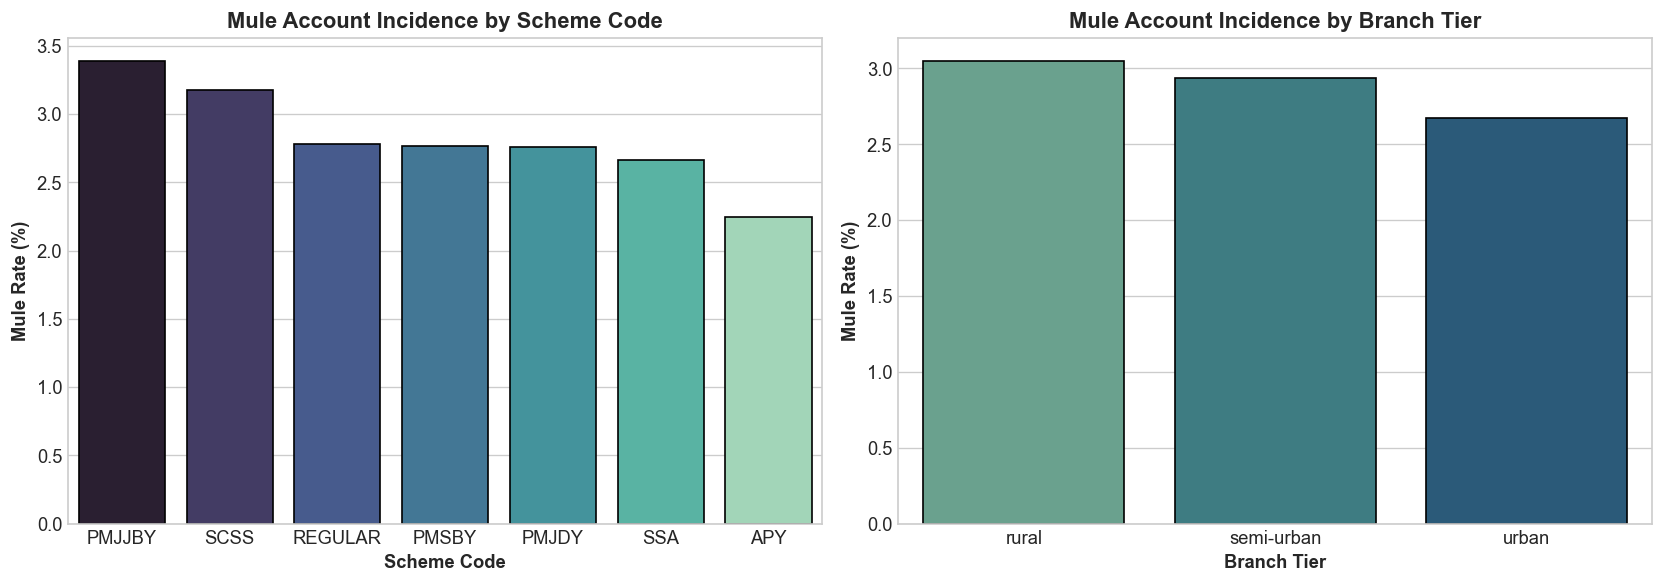

is_mule,Total,Mule,Mule_Rate_%
scheme_code,,,
PMJJBY,2891,98,3.389831
SCSS,1889,60,3.176284
REGULAR,69392,1930,2.781300
PMSBY,4772,132,2.766136
PMJDY,14341,396,2.761314
SSA,938,25,2.665245
APY,1868,42,2.248394


In [7]:
scheme_df = (
    train_merged.group_by(["scheme_code", "is_mule"])
    .len()
    .to_pandas()
    .pivot(index="scheme_code", columns="is_mule", values="len")
    .fillna(0)
    .rename(columns={0: "Legit", 1: "Mule"})
)
scheme_df["Total"] = scheme_df["Legit"] + scheme_df["Mule"]
scheme_df["Mule_Rate_%"] = (scheme_df["Mule"] / scheme_df["Total"]) * 100
scheme_df = scheme_df.sort_values("Mule_Rate_%", ascending=False)

branch_df = (
    train_merged.filter(pl.col("branch_type").is_not_null())
    .group_by(["branch_type", "is_mule"])
    .len()
    .to_pandas()
    .pivot(index="branch_type", columns="is_mule", values="len")
    .fillna(0)
    .rename(columns={0: "Legit", 1: "Mule"})
)
branch_df["Total"] = branch_df["Legit"] + branch_df["Mule"]
branch_df["Mule_Rate_%"] = (branch_df["Mule"] / branch_df["Total"]) * 100
branch_df = branch_df.sort_values("Mule_Rate_%", ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Scheme mule rate
sns.barplot(x=scheme_df.index, y=scheme_df["Mule_Rate_%"], ax=ax1, palette="mako", edgecolor="black")
ax1.set_title("Mule Account Incidence by Scheme Code", weight='bold')
ax1.set_ylabel("Mule Rate (%)", weight='bold')
ax1.set_xlabel("Scheme Code", weight='bold')

# Branch mule rate
sns.barplot(x=branch_df.index, y=branch_df["Mule_Rate_%"], ax=ax2, palette="crest", edgecolor="black")
ax2.set_title("Mule Account Incidence by Branch Tier", weight='bold')
ax2.set_ylabel("Mule Rate (%)", weight='bold')
ax2.set_xlabel("Branch Tier", weight='bold')

plt.tight_layout()
plt.show()

display(scheme_df[["Total", "Mule", "Mule_Rate_%"]])


## 6. Transaction Behavioral Signatures (Sample Batch Analysis)
We now examine sample transaction batches to evaluate behavioral fingerprints:
1. **Structuring below ₹50,000 threshold**: Laundering syndicates frequently route transactions between ₹45,000 and ₹49,999 to avoid mandatory PAN reporting.
2. **Round Amount Multiples**: Preference for whole multiples of ₹5,000 or ₹10,000.
3. **Channel Preference**: Digital high-velocity channels (UPI / IMPS) vs traditional branch channels.


In [8]:
# Sample 5 partitions from Dataset/transactions/batch-1/
mule_id_list = train_labels.filter(pl.col("is_mule") == 1)["account_id"].to_list()
legit_id_list = train_labels.filter(pl.col("is_mule") == 0)["account_id"].to_list()

mule_ids_set = set(mule_id_list)
legit_ids_set = set(legit_id_list)

sample_files = sorted(glob.glob("Dataset/transactions/batch-1/part_*.parquet"))[:5]
print(f"Reading {len(sample_files)} sample transaction partitions...")

tx_dfs = [pl.read_parquet(f) for f in sample_files]
tx_sample = pl.concat(tx_dfs)

# Filter to labeled accounts
tx_labeled = tx_sample.with_columns(
    pl.when(pl.col("account_id").is_in(mule_id_list))
    .then(1)
    .when(pl.col("account_id").is_in(legit_id_list))
    .then(0)
    .otherwise(None)
    .alias("is_mule")
).filter(pl.col("is_mule").is_not_null())

mule_tx = tx_labeled.filter(pl.col("is_mule") == 1)
legit_tx = tx_labeled.filter(pl.col("is_mule") == 0)

print(f"Sample contains {len(tx_labeled):,} labeled transactions:")
print(f"- Mule Transactions: {len(mule_tx):,} across {mule_tx['account_id'].n_unique()} accounts")
print(f"- Legit Transactions: {len(legit_tx):,} across {legit_tx['account_id'].n_unique()} accounts")


Reading 5 sample transaction partitions...
Sample contains 2,966,884 labeled transactions:
- Mule Transactions: 75,437 across 35 accounts
- Legit Transactions: 2,891,447 across 1139 accounts


--- PMLA Structuring Patterns (₹45,000 - ₹49,999) ---
Mule Structuring Rate  : 0.685% (517 transactions)
Legit Structuring Rate : 0.552% (15950 transactions)
Relative Structuring Elevation in Mules: 1.24x


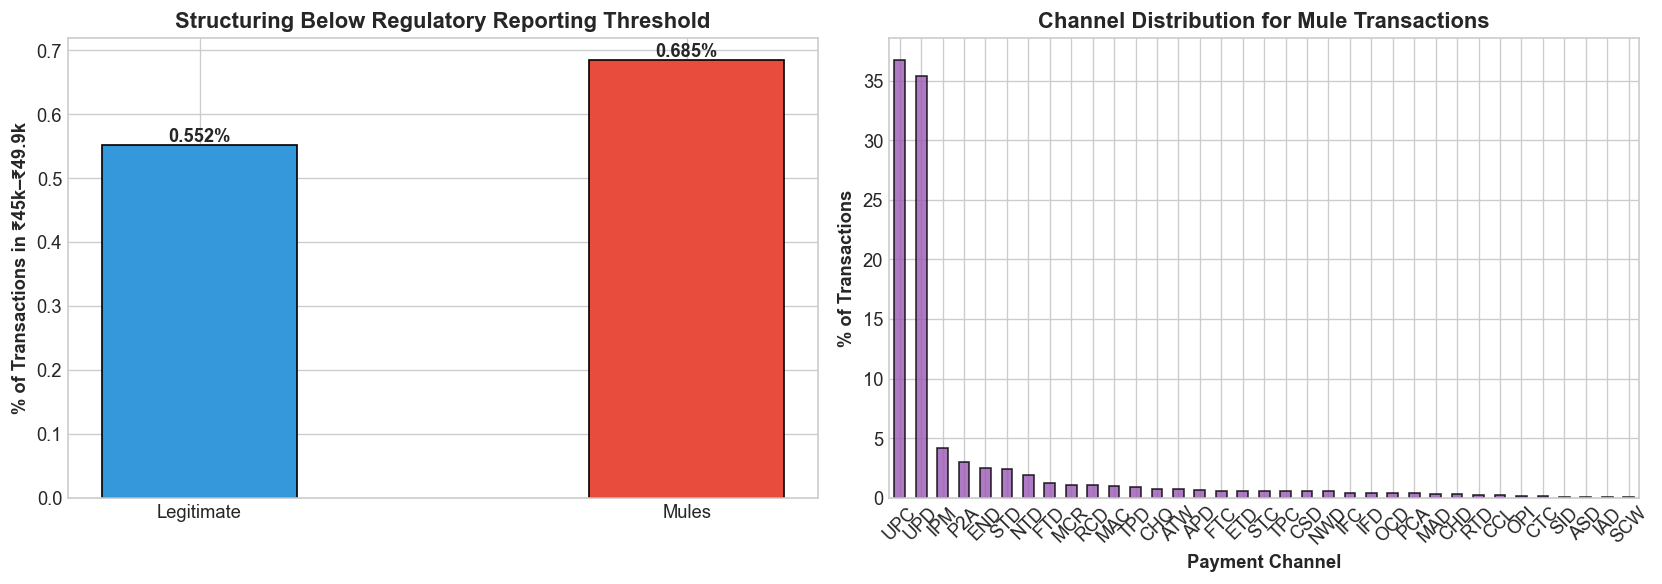

In [9]:
# 1. PMLA ₹50k Structuring Detection (₹45,000 - ₹49,999)
mule_struct = mule_tx.filter((pl.col("amount") >= 45000) & (pl.col("amount") < 50000)).shape[0]
legit_struct = legit_tx.filter((pl.col("amount") >= 45000) & (pl.col("amount") < 50000)).shape[0]

pct_mule_struct = (mule_struct / len(mule_tx)) * 100 if len(mule_tx) > 0 else 0
pct_legit_struct = (legit_struct / len(legit_tx)) * 100 if len(legit_tx) > 0 else 0

print("--- PMLA Structuring Patterns (₹45,000 - ₹49,999) ---")
print(f"Mule Structuring Rate  : {pct_mule_struct:.3f}% ({mule_struct} transactions)")
print(f"Legit Structuring Rate : {pct_legit_struct:.3f}% ({legit_struct} transactions)")
print(f"Relative Structuring Elevation in Mules: {pct_mule_struct / (pct_legit_struct + 1e-6):.2f}x")

# Channel distribution
mule_chan = mule_tx.group_by("channel").len().sort("len", descending=True).to_pandas()
legit_chan = legit_tx.group_by("channel").len().sort("len", descending=True).to_pandas()
mule_chan["pct"] = (mule_chan["len"] / len(mule_tx)) * 100
legit_chan["pct"] = (legit_chan["len"] / len(legit_tx)) * 100

chan_comp = mule_chan[["channel", "pct"]].rename(columns={"pct": "Mule_%"})
chan_comp = chan_comp.merge(legit_chan[["channel", "pct"]].rename(columns={"pct": "Legit_% propagate"}), on="channel", how="left")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Structuring comparison
ax1.bar(["Legitimate", "Mules"], [pct_legit_struct, pct_mule_struct], color=['#3498db', '#e74c3c'], edgecolor='black', width=0.4)
ax1.set_ylabel("% of Transactions in ₹45k–₹49.9k", weight='bold')
ax1.set_title("Structuring Below Regulatory Reporting Threshold", weight='bold')
for i, v in enumerate([pct_legit_struct, pct_mule_struct]):
    ax1.text(i, v + 0.005, f"{v:.3f}%", ha='center', weight='bold')

# Top channels comparison
mule_chan.set_index("channel")["pct"].plot(kind='bar', ax=ax2, color='#9b59b6', edgecolor='black', alpha=0.8)
ax2.set_title("Channel Distribution for Mule Transactions", weight='bold')
ax2.set_ylabel("% of Transactions", weight='bold')
ax2.set_xlabel("Payment Channel", weight='bold')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


## 7. Strategic Conclusions & Modeling Roadmap

### Summary of Discoveries:
1. **Target Metric**: Due to the **35:1 imbalance**, our models must be optimized and selected via **PR-AUC (Precision-Recall AUC)** and **F1-score**, not accuracy.
2. **Ignore Naive Freeze Features**: Relying heavily on `account_status == 'frozen'` causes severe false positive rate inflation on legitimate accounts and fails to detect >50% of real active mules.
3. **Core Engineered Features Required**:
   - **Velocity & Turnover Ratio**: $\text{Turnover} = \frac{\text{Total Debit Amount}}{\text{Total Credit Amount} + \epsilon}$ (mules rapidly drain inflows).
   - **Threshold Structuring Ratios**: Fraction of transactions in ₹45k–₹49.9k.
   - **Digital Channel Share**: UPI/IMPS transaction ratios vs traditional branch channels.
   - **Account Age & Recency**: Days since mobile update relative to transaction bursts.
   - **Temporal Burst Windows**: Localizing rapid fund movement windows.
